# Predicting single-cell cell-cycle state from label-free phase

**Question.** Cell-cycle position is a major driver of single-cell morphological heterogeneity. If an arbitrary
**label-free phase** image of a cell tells us where that cell is in the cycle, we can later regress the cycle out and
read a cleaner perturbation phenotype.

**Data.** OPS0077 (Biohub Altair, A549), the non-targeting (NTC) population only, so the variation is cell-cycle, not
perturbation. Every cell has:
- per-cell **phase** OrganelleProfiler features (`obsm['X_phase']`, label-free),
- a 4i **cell-cycle readout** measured on the same cell: **DNA content** (DAPI, rounds 2 to 4, per-cell background),
  **pRb** (restriction point), and a DNA x pRb **cycle stage**.

We train phase -> the 4i readout with held-out validation (folds grouped by imaging tile, so no tile leaks between
train and test), and compare against a cell-size-only baseline and a shuffled-label null.

In [1]:
import numpy as np, pandas as pd, anndata as ad
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, roc_auc_score, roc_curve
import warnings; warnings.filterwarnings('ignore')

# Read the RAW per-cell phase table and the aligned cell-cycle frame (targets); all preprocessing is done inside each
# fold, so nothing from the test cells leaks into scaling or imputation.
import os
def find(*names):
    roots = ['/srv/team/data/crossmodal/ops0077_ntc',
             'data', '.']
    for n in names:
        for r in roots:
            if os.path.exists(f'{r}/{n}'): return f'{r}/{n}'
    raise FileNotFoundError(names)

ph = ad.read_h5ad(find('OPS0077_NTC_phase_OrganelleProfiler.h5ad'))
fr = pd.read_parquet(find('OPS0077_NTC_cellcycle_frame.parquet'))
ph.obs_names = ph.obs['cell_key'].astype(str) if 'cell_key' in ph.obs else ph.obs_names.astype(str)
cells = ph.obs_names[ph.obs_names.isin(fr.index)]
ph, fr = ph[cells], fr.loc[cells]
# keep phase features present in >=85% of cells (drops never-populated fluor-contact families)
present = np.isfinite(np.asarray(ph.X)).mean(0) >= 0.85
Xp = np.asarray(ph.X, np.float32)[:, present]
print('cells', ph.n_obs, '| phase features kept', int(present.sum()), 'of', present.size)

cells 52189 | phase features kept 1740 of 3317


## Targets from 4i (the ground truth phase has to recover)
- `dna_content_log2`: relative DNA content (0 = G1/2N, +1 = G2-M/4N).
- `log2_pRb`: restriction-point marker.
- G1 vs G2/M label: 2N low-DNA cells vs 4N high-DNA cells (the clean ends of the cycle).
We keep only cells with reliable DNA, and show the result again on the subset with a trusted live-to-fixed match.

In [2]:
rel = (fr['dna_reliable'].astype(str) == 'True').values
groups_all = fr['tile_pheno'].astype(str).values
area = np.c_[fr['nuclear_area_4i'].astype(float), fr['cell_area_4i'].astype(float)]
area = np.where(np.isfinite(area), area, np.nanmedian(area, axis=0))   # a few cells lack a 4i area

def subset(mask):
    y_dna = fr['dna_content_log2'].astype(float).values[mask]
    y_prb = fr['log2_pRb'].astype(float).values[mask]
    g = np.full(mask.sum(), -1); g[y_dna < 0.25] = 0; g[y_dna > 0.65] = 1
    return Xp[mask], area[mask], y_dna, y_prb, g, groups_all[mask]

print('reliable-DNA cells:', int(rel.sum()))

reliable-DNA cells: 36014


## Method
Held-out 5-fold, folds grouped by tile. Inside each fold: PCA(100) on the phase features (fit on train only), then
RidgeCV for the continuous targets and logistic regression for G1 vs G2/M. Baselines use only nuclear and cell area.

In [3]:
def prep(Xtr, Xte, pca):
    # fitted on train only: median-impute -> robust-scale (median/IQR) -> clip +-5 -> PCA(100)
    imp = SimpleImputer(strategy='median').fit(Xtr)
    sc = RobustScaler(quantile_range=(10,90)).fit(imp.transform(Xtr))
    f = lambda Z: np.clip(sc.transform(imp.transform(Z)), -5, 5)
    Xtr2, Xte2 = f(Xtr), f(Xte)
    if pca and Xtr2.shape[1] > 100:
        p = PCA(100, random_state=0).fit(Xtr2); Xtr2, Xte2 = p.transform(Xtr2), p.transform(Xte2)
    return Xtr2, Xte2

def oof_r2(X, y, groups, pca=True):
    pred = np.zeros_like(y)
    for tr, te in GroupKFold(5).split(X, y, groups):
        Xtr, Xte = prep(X[tr], X[te], pca)
        pred[te] = RidgeCV(alphas=np.logspace(-2,5,15)).fit(Xtr, y[tr]).predict(Xte)
    return r2_score(y, pred), pred

def oof_auc(X, g, groups, pca=True, shuffle=False):
    m = g >= 0; X, gg, gr = X[m], g[m], groups[m]
    if shuffle: gg = np.random.default_rng(0).permutation(gg)
    pp = np.zeros(len(gg))
    for tr, te in GroupKFold(5).split(X, gg, gr):
        Xtr, Xte = prep(X[tr], X[te], pca)
        pp[te] = LogisticRegression(C=0.1, max_iter=3000).fit(Xtr, gg[tr]).predict_proba(Xte)[:,1]
    return roc_auc_score(gg, pp), gg, pp

In [4]:
rows = []
trusted = rel & (fr['pheno_to_fixed_distance_px'].astype(float) < 25).values
for label, mask in [('all reliable-DNA cells', rel),
                    ('trusted live->fixed match', trusted)]:
    Xm, ar, y_dna, y_prb, g, gr = subset(mask)
    r_dna, pred_dna = oof_r2(Xm, y_dna, gr)
    r_prb, _ = oof_r2(Xm, y_prb, gr)
    r_dna_sz, _ = oof_r2(ar, y_dna, gr, pca=False)
    auc, gg, pp = oof_auc(Xm, g, gr)
    auc_sz, _, _ = oof_auc(ar, g, gr, pca=False)
    auc_null, _, _ = oof_auc(Xm, g, gr, shuffle=True)
    rows.append(dict(subset=label, n=int(mask.sum()),
                     DNA_R2_phase=round(r_dna,3), DNA_R2_size=round(r_dna_sz,3),
                     pRb_R2_phase=round(r_prb,3),
                     G1vsG2M_AUC_phase=round(auc,3), AUC_size=round(auc_sz,3), AUC_null=round(auc_null,3)))
res = pd.DataFrame(rows); res

,subset,n,DNA_R2_phase,DNA_R2_size,pRb_R2_phase,G1vsG2M_AUC_phase,AUC_size,AUC_null
0,all reliable-DNA cells,36014,0.481,0.156,0.199,0.935,0.748,0.505
1,trusted live->fixed match,12691,0.623,0.181,0.224,0.973,0.772,0.503


## Result

Phase morphology carries clear cell-cycle information well beyond cell size, and it is strongest at the clean ends of
the cycle (G1 vs G2/M). pRb is partly readable from phase; DNA content is recovered at R2 ~ 0.5 to 0.6.

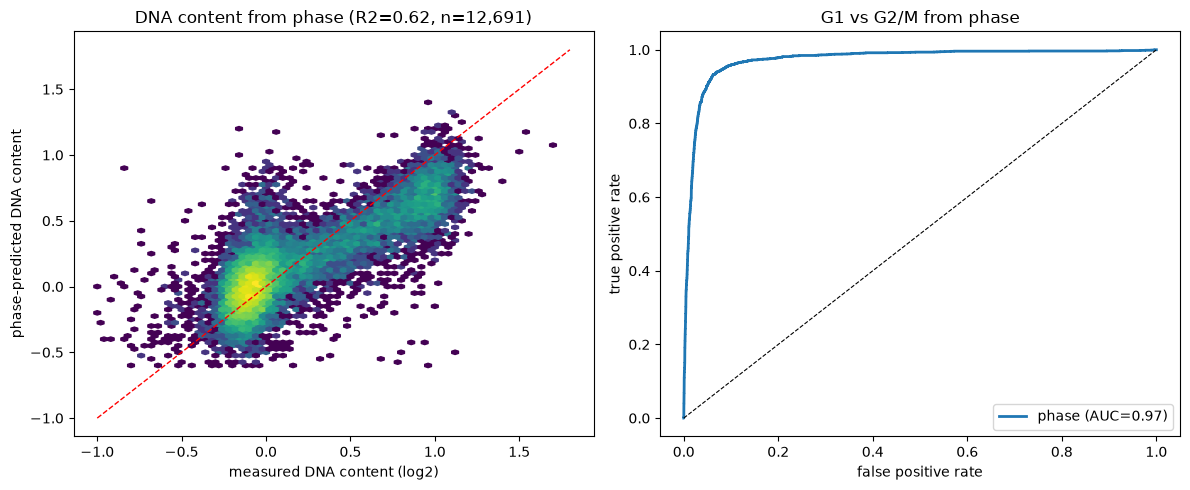

In [5]:
# figure on the trusted subset
mask = rel & (fr['pheno_to_fixed_distance_px'].astype(float) < 25).values
Xm, ar, y_dna, y_prb, g, gr = subset(mask)
r_dna, pred_dna = oof_r2(Xm, y_dna, gr); auc, gg, pp = oof_auc(Xm, g, gr)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].hexbin(y_dna, pred_dna, gridsize=70, bins='log', extent=(-1,1.8,-0.6,1.4))
ax[0].plot([-1,1.8],[-1,1.8],'r--',lw=1); ax[0].set_xlabel('measured DNA content (log2)')
ax[0].set_ylabel('phase-predicted DNA content'); ax[0].set_title(f'DNA content from phase (R2={r_dna:.2f}, n={len(y_dna):,})')
fpr, tpr, _ = roc_curve(gg, pp)
ax[1].plot(fpr, tpr, lw=2, label=f'phase (AUC={auc:.2f})'); ax[1].plot([0,1],[0,1],'k--',lw=0.8)
ax[1].set_xlabel('false positive rate'); ax[1].set_ylabel('true positive rate'); ax[1].set_title('G1 vs G2/M from phase'); ax[1].legend()
plt.tight_layout(); plt.savefig('phase_cycle_result.png', dpi=100); plt.show()

## Write the per-cell phase prediction back into the dataset
We train one phase -> DNA-content model on all reliable cells (out-of-fold, so each cell's prediction is held-out) and
store it as `obs['phase_predicted_dna']`, a per-cell phase-based cell-cycle coordinate for the correction step.

In [6]:
_, pred = oof_r2(Xp[rel], fr['dna_content_log2'].astype(float).values[rel], groups_all[rel])
pred_s = pd.Series(np.nan, index=cells); pred_s[cells[rel]] = pred    # held-out per-cell phase cycle coordinate

mm_path = find('OPS0077_NTC_Multimodal_4i_Phase_DNA.h5ad')
A = ad.read_h5ad(mm_path)
A.obs['phase_predicted_dna'] = pred_s.reindex(A.obs_names).values
try:
    A.write_h5ad(mm_path, compression='gzip'); out = mm_path
except Exception:
    out = 'OPS0077_NTC_Multimodal_4i_Phase_DNA_withpred.h5ad'; A.write_h5ad(out, compression='gzip')
print('wrote', out, '| predicted cells', int(np.isfinite(A.obs['phase_predicted_dna'].astype(float)).sum()))

wrote /srv/team/data/crossmodal/ops0077_ntc/OPS0077_NTC_Multimodal_4i_Phase_DNA.h5ad | predicted cells 36014


## Takeaways
- **Label-free phase predicts single-cell cell-cycle state.** G1 vs G2/M held-out AUC ~0.94 to 0.97, far above the
  cell-size baseline (~0.75) and the shuffled null (~0.50); DNA content R2 ~0.5 to 0.6.
- The signal is **not just cell size**: the full phase morphology adds a large margin over nuclear + cell area.
- Each cell now has a phase-based cell-cycle coordinate (`phase_predicted_dna`), the input for regressing the cycle out
  to get a cleaner perturbation representation (next step).
- Scope: NTC cells of one screen; folds grouped by tile. pRb is partly predictable; p21 is flat across the cycle in NTC
  cells and is not used here.